# Find the java codes here: [Java code](https://drive.google.com/drive/folders/1Q4Nqs6GtzkgUX8nq4fpT-D6qwEERedEV?usp=sharing)

# Topics for mid
- Multi-dimentation array (Code, Math (2-types))
- LL (any of the 8 types can be in the exam)
- Hashing (any of the 4 LL types can be in the exam)
- Stack, Queue (The code of stack and queue will always be given. You need to call the methods)

## Theory

---------------------------------------------------------------------
- Summer2025 Q1
   * Q1. i) Math in Multi-dimentional array section

   * Q1. ii) Linked list is better. Linked list memory O(n) for length n. Hash table memory O(m+n) m for length of array

   * Q1. iii) Pop - O(n) and peek O(n)
---------------------------------------------------------------------
- Fall2025 Q4
  *   Q1. Math in Multi-dimentional array section
  *   [rest of the theory](https://docs.google.com/document/d/1cdzlfsoO1VoWchxyX4tyIrJPsg3qkiWT4k2Hgq-TJFo/edit?usp=sharing)---------------------------------------------------------------------
- Spring2026 Q4
    *   [Solution link](https://docs.google.com/document/d/1JHlfVQK9JZY0v9ElEL0Y1-ucSWiC-XNP/edit?usp=sharing&ouid=100216673605729372437&rtpof=true&sd=true)



# Stack Questions

## Fall2025: Q3: Merge stacks

In [ ]:
import numpy as np
# ============================================================
# GIVEN --- DO NOT MODIFY
# ============================================================
class Node:
    def __init__(self, data):
        self.data = data
        self.next = None

class Stack:
    def __init__(self):
        self.top = None
        self.size = 0

    def isEmpty(self):
        return self.size == 0

    def push(self, data):
        new_node = Node(data)
        new_node.next = self.top
        self.top = new_node
        self.size += 1

    def pop(self):
        if self.isEmpty():
            raise IndexError("Underflow: Pop from empty stack")
        popped_data = self.top.data
        self.top = self.top.next
        self.size -= 1
        return popped_data

    def peek(self):
        if self.isEmpty():
            raise IndexError("Underflow: Peek from empty stack")
        return self.top.data

    def toString(self):
        a = ""
        temp = self.top
        while temp is not None:
            a += str(temp.data) + " "
            temp = temp.next
        return a

In [ ]:
# ============================================================
# mergeStacks()
# ============================================================
def mergeStacks1(stack1, stack2):
    """
    Merges two stacks sorted in non-decreasing order (top -> bottom)
    into one stack sorted in non-decreasing order (top -> bottom).
    Uses ONLY stacks.
    """

    # Step 1: Reverse stack1 into temp1
    temp1 = Stack()
    while not stack1.isEmpty():
        temp1.push(stack1.pop())   # Now largest is on top

    # Step 2: Reverse stack2 into temp2
    temp2 = Stack()
    while not stack2.isEmpty():
        temp2.push(stack2.pop())   # Largest on top

    # Step 3: Merge into final stack
    merged = Stack()

    while not temp1.isEmpty() or not temp2.isEmpty():

        if temp1.isEmpty():
            merged.push(temp2.pop())

        elif temp2.isEmpty():
            merged.push(temp1.pop())

        else:
            if temp1.peek() >= temp2.peek():
                merged.push(temp1.pop())
            else:
                merged.push(temp2.pop())

    return merged

# ============================================================
# DRIVER CODE
# ============================================================
print("===== SAMPLE MERGE TEST =====")

# stack1 = -2 3 6 6 10 (top is -2)
stack1 = Stack()
for v in [10, 6, 6, 3, -2]:  # reversed because push puts on top
    stack1.push(v)

# stack2 = 0 4 6 8 (top is 0)
stack2 = Stack()
for v in [8, 6, 4, 0]:
    stack2.push(v)

print("Stack 1 (top → bottom):", stack1.toString())
print("Stack 2 (top → bottom):", stack2.toString())

merged = mergeStacks1(stack1, stack2)

print("\nMerged Stack (top → bottom):", merged.toString())

===== SAMPLE MERGE TEST =====
Stack 1 (top → bottom): -2 3 6 6 10 
Stack 2 (top → bottom): 0 4 6 8 

Merged Stack (top → bottom): -2 0 3 4 6 6 6 8 10 


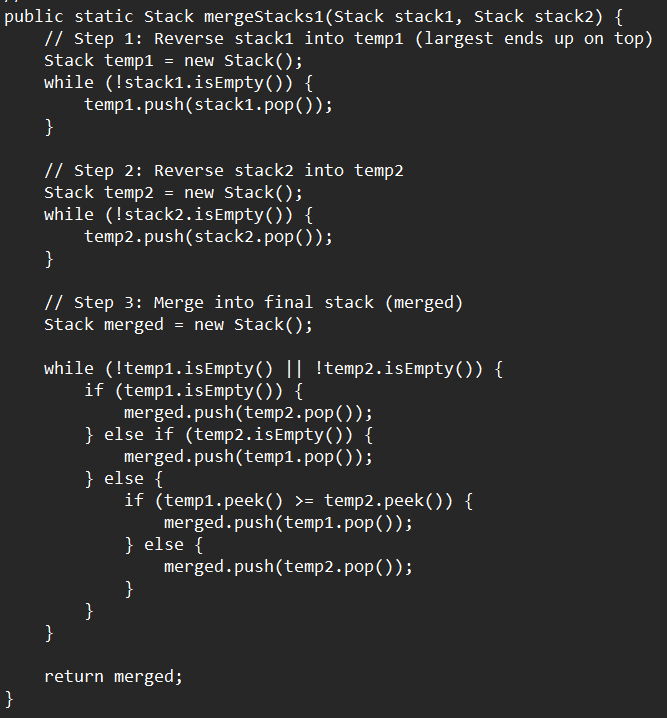

In [ ]:
def mergeStacks3(stack1, stack2):
    temp = Stack()     # temporary reversed output
    result = Stack()   # final merged stack

    # Merge while both stacks have data
    while (not stack1.isEmpty()) and (not stack2.isEmpty()):
        # Compare WITHOUT popping
        if stack1.peek() < stack2.peek():
            temp.push(stack1.pop())   # pop ONLY the smaller one
        else:
            temp.push(stack2.pop())

    # Add remaining elements from stack1
    while not stack1.isEmpty():
        temp.push(stack1.pop())

    # Add remaining elements from stack2
    while not stack2.isEmpty():
        temp.push(stack2.pop())

    # Reverse temp into result to restore top-smallest order
    while not temp.isEmpty():
        result.push(temp.pop())

    return result


# ============================================================
# DRIVER CODE (For testing mergeStacks)
# ============================================================
print("===== SAMPLE MERGE TEST =====")

# -------------------------------------------------------------
# stack1 should represent:  -2 → 3 → 6 → 6 → 10   (top is -2)
# But since push() places elements at the TOP,
# we push values in reverse order to build the stack correctly.
# -------------------------------------------------------------
stack1 = Stack()
for v in [10, 6, 6, 3, -2]:
    stack1.push(v)

# -------------------------------------------------------------
# stack2 should represent:  0 → 4 → 6 → 8   (top is 0)
# Again, push in reverse.
# -------------------------------------------------------------
stack2 = Stack()
for v in [8, 6, 4, 0]:
    stack2.push(v)

# Display initial stacks
print("Stack 1 (top → bottom):", stack1.toString())
print("Stack 2 (top → bottom):", stack2.toString())

# -------------------------------------------------------------
# Call mergeStacks to merge two sorted stacks
# -------------------------------------------------------------
merged = mergeStacks3(stack1, stack2)

# Display final result
print("\nMerged Stack (top → bottom):", merged.toString())


===== SAMPLE MERGE TEST =====
Stack 1 (top → bottom): -2 3 6 6 10 
Stack 2 (top → bottom): 0 4 6 8 

Merged Stack (top → bottom): -2 0 3 4 6 6 6 8 10 


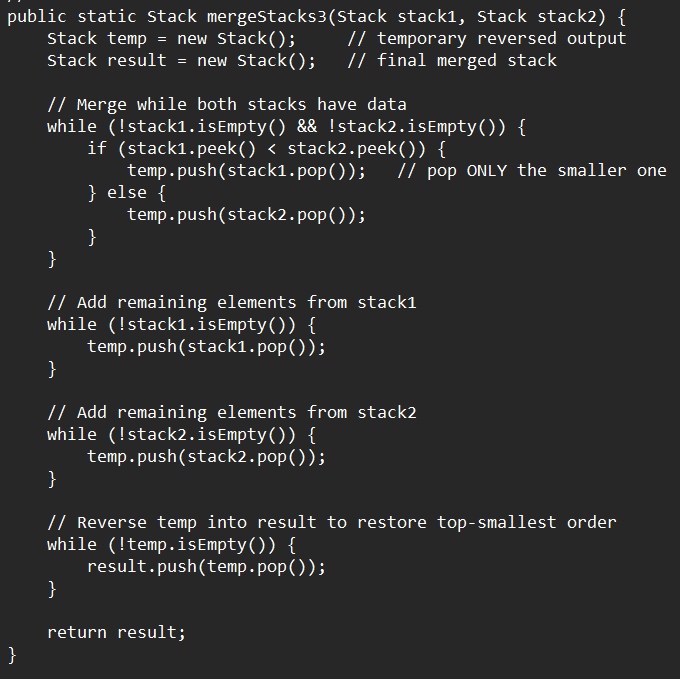

## Summer2025: DepositSum

In [ ]:
import numpy as np

# GIVEN---NO NEED TO WRITE
class Node:
    def __init__(self, data):
        self.data = data
        self.next = None

# ## Given stack class
class Stack:
    def __init__(self):
        self.top = None  # Represents the top of the stack--head here
        self.size = 0    # Tracks the size of the stack

    def isEmpty(self):
        return self.size == 0

    def push(self, data): # Prepend--head changes
        new_node = Node(data)
        new_node.next = self.top  # New node points to the current top
        self.top = new_node       # Update the top to the new node
        self.size += 1            # Increment size

    def pop(self): # remove top head--index 0
        if self.isEmpty():
            raise IndexError("Underflow: Pop from empty stack")
        popped_data = self.top.data  # Retrieve the data of the top node
        self.top = self.top.next     # Update the top to the next node
        self.size -= 1               # Decrement size
        return popped_data

    def peek(self):
        if self.isEmpty():
            raise IndexError("Underflow: Peek from empty stack")
        return self.top.data

    def toString(self):
        a = ""
        temp = self.top
        while temp is not None:
            a += str(temp.data) + " "
            temp = temp.next
        return a


In [ ]:
def stackToStringWithTop(st):
    temp = Stack()
    values = []

    # Store elements from top to bottom
    while not st.isEmpty():
        val = st.pop()
        values.append(val)
        temp.push(val)

    # Restore original stack
    while not temp.isEmpty():
        st.push(temp.pop())

    return "TOP -> " + str(values)


def depositSum(st, window):
    print("Given stack:", stackToStringWithTop(st))

    result = Stack()

    # Process each window from the top of the stack
    while not st.isEmpty():
        deposit_sum = 0
        count = 0

        # Process at most 'window' number of elements
        while count < window and not st.isEmpty():
            val = st.pop()

            # Add only deposits
            if val > 0:
                deposit_sum += val

            count += 1

        # Store sum of current window
        result.push(deposit_sum)

    # Put results back into the original stack
    while not result.isEmpty():
        st.push(result.pop())

    print("Returned stack:", stackToStringWithTop(st))
    return st


# Create and populate stack
stack = Stack()

# 12 will be at the TOP
for value in [14, 9, -2, -6, -20, -7, 15, 8, -3, 12]:
    stack.push(value)

depositSum(stack, 4)

Given stack: TOP -> [12, -3, 8, 15, -7, -20, -6, -2, 9, 14]
Returned stack: TOP -> [35, 0, 23]


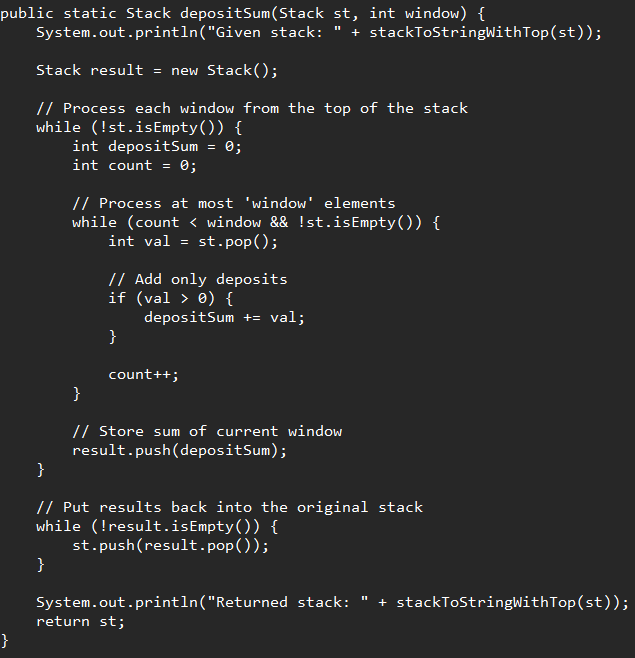

#Hashing

## Summer2025: Insert

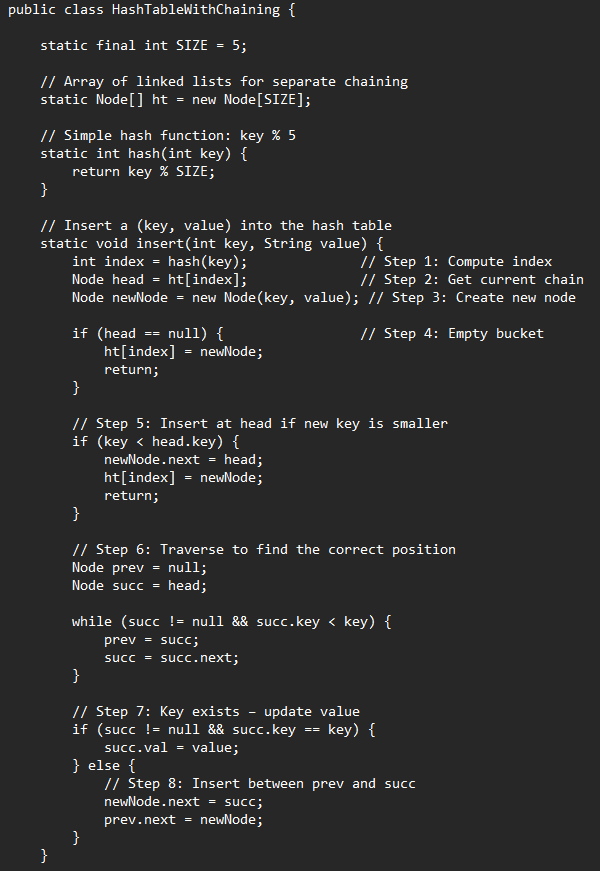

In [ ]:
# Define the Node class (singly linked list node)
class Node:
    def __init__(self, key, val, next=None):
        self.key = key
        self.val = val
        self.next = next

# Sample hash function
def hash(key):
    return key % 5  # Assuming fixed size 5 for ht

# Global hashtable with 5 buckets
ht = [None for _ in range(5)]


def insert(key, value):
    # Step 1: Compute the index for the key using the provided hash function
    index = hash(key)

    # Step 2: Get the head of the linked list (chain) at that index
    head = ht[index]

    # Step 3: Create a new node with the given key and value
    new_node = Node(key, value)

    # Step 4: If the bucket is empty, insert the new node directly
    if head is None:
        ht[index] = new_node
        return

    # Step 5: If the new key is smaller than the head's key, insert at the head
    # Prepend code
    if key < head.key:
        new_node.next = head   # Point new node to current head
        ht[index] = new_node   # Update head of chain
        return

    # Step 6: Traverse the chain to find the correct position for insertion
    prev = None
    succ = head

    # Move through the list until we find a node with a key >= new key
    while succ and succ.key < key:
        prev = succ
        succ = succ.next

    # Step 7: If a node with the same key exists, replace its value
    # Update value
    if succ and succ.key == key:
        succ.val = value  # Update the existing value, no insertion
    else:
        # Step 8: Otherwise, insert the new node between prev and succ
        new_node.next = succ  # Link new node to successor
        prev.next = new_node  # Link previous node to new node

# Print the hashtable
def print_hashtable():
    for i in range(len(ht)):
        print(f"Index {i}:", end=" ")
        node = ht[i]
        while node:
            print(f"({node.key}, {node.val})", end=" -> ")
            node = node.next
        print("None")

# Setup initial hashtable as per the example
ht[0] = Node(3, "CAT", Node(4, "EELS"))
ht[1] = Node(5, "LION")
ht[2] = Node(2, "DOG", Node(9, "CROW"))
ht[3] = Node(27, "WOLF")
ht[4] = Node(10, "FISH", Node(11, "OWL"))

print("Before insertion:")
print_hashtable()

# Insert (8, "GOAT")
insert(8, "GOAT")

print("\nAfter inserting (8, 'GOAT'):")
print_hashtable()


Before insertion:
Index 0: (3, CAT) -> (4, EELS) -> None
Index 1: (5, LION) -> None
Index 2: (2, DOG) -> (9, CROW) -> None
Index 3: (27, WOLF) -> None
Index 4: (10, FISH) -> (11, OWL) -> None

After inserting (8, 'GOAT'):
Index 0: (3, CAT) -> (4, EELS) -> None
Index 1: (5, LION) -> None
Index 2: (2, DOG) -> (9, CROW) -> None
Index 3: (8, GOAT) -> (27, WOLF) -> None
Index 4: (10, FISH) -> (11, OWL) -> None


# Linked List questions

## Fall2025: Q2: Range Reverse (Can be solved in lot of ways)


### Solution using without any methods (Most clumsy way to do it, not recommended)

In [ ]:
def rangeReverse2(dHead, start, end):
    # dHead : dummy head of the linked list (its next points to the real head)
    # start : index of the first node to reverse
    # end   : index of the last node to reverse

    # -------- 1. Move beforeNode to the node just BEFORE 'start' --------
    beforeNode = dHead           # Start from the dummy head
    for i in range(1, start):    # Move step by step until we reach (start-1)-th node
        if beforeNode.next is None:   # start is beyond list length -> nothing to do
            return
        beforeNode = beforeNode.next

    # Now:
    # beforeNode -> node just BEFORE the segment we want to reverse
    startNode = beforeNode.next       # Node at position 'start'
    if startNode is None:
        # start is exactly one past the last index -> nothing to reverse
        return

    # These two pointers will be used for the actual reversal
    prev = None
    curr = startNode

    # -------- 2. Reverse the segment from 'start' to 'end' --------
    i = start
    while curr is not None and i <= end:  # stop if we hit end of list OR end index
        nxt = curr.next         # 1. Remember the next node
        curr.next = prev        # 2. Reverse link
        prev = curr             # 3. Move prev forward
        curr = nxt              # 4. Move curr forward
        i += 1

    # After the loop:
    # prev      = head of the reversed segment
    # curr      = node right AFTER the reversed segment (or None)
    # startNode = tail of the reversed segment

    # -------- 3. Reconnect the reversed segment with the rest of the list --------
    beforeNode.next = prev      # Connect node before segment to new head
    startNode.next = curr       # Tail of reversed segment to the remainder


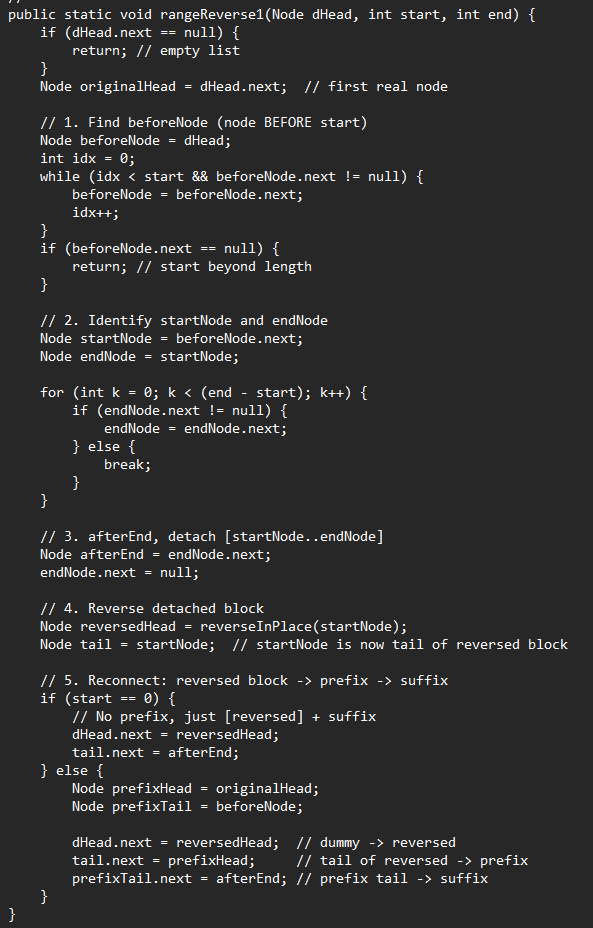

### Solution using ReverseInplace

In [ ]:
############################################
# reverseInPlace (helper)
############################################
def reverseInPlace(head):
    prev = None
    current = head
    while current:
        nxt = current.next
        current.next = prev
        prev = current
        current = nxt
    return prev   # new head


############################################
# rangeReverse1 (MAIN FUNCTION)
############################################
def rangeReverse1(dHead, start, end):
    """
    Reverse nodes from index [start..end],
    move the reversed block to the FRONT,
    then append the remaining nodes afterward.
    """

    if dHead.next is None:
        return  # empty list, nothing to do

    # Save the original first real node (start of prefix if start > 0)
    originalHead = dHead.next

    # -------- 1. Find beforeNode (node just BEFORE 'start') --------
    beforeNode = dHead
    idx = 0
    while idx < start and beforeNode.next:
        beforeNode = beforeNode.next
        idx += 1

    # If start is beyond list length -> nothing to reverse
    if beforeNode.next is None:
        return

    # -------- 2. Identify startNode and endNode of the segment --------
    startNode = beforeNode.next           # first node in [start..]
    endNode = startNode

    for _ in range(end - start):
        if endNode.next:
            endNode = endNode.next
        else:
            break                         # end index goes past list

    # Node after the reversed segment (suffix)
    afterEnd = endNode.next

    # Detach [startNode ... endNode] from the list
    endNode.next = None

    # -------- 3. Reverse the detached block --------
    reversedHead = reverseInPlace(startNode)
    tail = startNode        # startNode is now the TAIL of the reversed block

    # -------- 4. Reconnect: reversed block -> prefix -> suffix --------

    if start == 0:
        # No prefix exists, only: [reversed block] + suffix
        dHead.next = reversedHead     # dummy -> reversed block
        tail.next = afterEnd          # tail of reversed -> suffix
    else:
        # There IS a prefix: originalHead ... beforeNode
        prefixHead = originalHead
        prefixTail = beforeNode

        # Final order:
        # dummy -> reversed block -> prefix -> suffix

        dHead.next = reversedHead     # dummy -> reversed block
        tail.next = prefixHead        # tail of reversed -> prefix head
        prefixTail.next = afterEnd    # prefix tail -> suffix


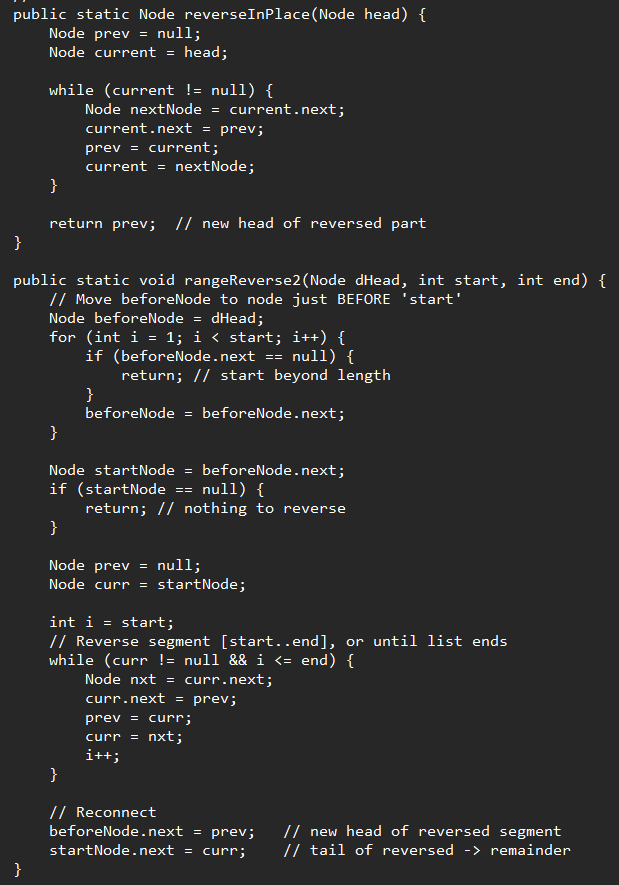

### Solution using getNode

In [ ]:
# ===============================
# getNode(head, idx) - 0-based
# Returns node at index idx among real nodes
# head is the DUMMY HEAD (head.next = index 0)
# ===============================
def getNode(head, idx):
    current = head.next  # index 0
    pos = 0
    while current is not None and pos < idx:
        current = current.next
        pos += 1
    return current  # may be None if idx invalid


# ===============================
# rangeReverse2 using getNode()
# ===============================
def rangeReverse3(dHead, start, end):

    # --- 1. Find beforeNode (node BEFORE start index) ---
    if start == 0:
        beforeNode = dHead
    else:
        beforeNode = getNode(dHead, start - 1)

    # If beforeNode is None → start index is invalid → nothing to do
    if beforeNode is None:
        return

    # startNode = first node of segment
    startNode = beforeNode.next

    # If startNode is None → start beyond list → nothing to reverse
    if startNode is None:
        return

    # --- 2. Reverse from start to end safely ---
    prev = None
    curr = startNode

    i = start
    while curr is not None and i <= end:
        nxt = curr.next      # save next
        curr.next = prev     # reverse link
        prev = curr          # move prev
        curr = nxt           # move curr
        i += 1

    # After reversal:
    # prev  = head of reversed segment
    # curr  = node AFTER the reversed segment
    # startNode = tail of reversed segment

    # --- 3. Reconnect the list ---
    beforeNode.next = prev    # attach reversed segment
    startNode.next = curr     # attach tail to the remainder


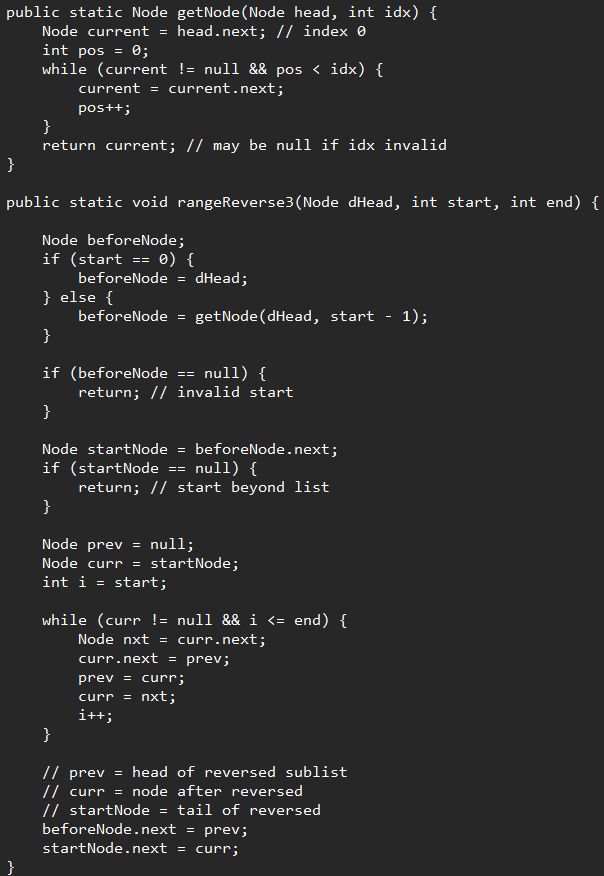

### Solution using getNode, getsize

In [ ]:
# ===============================
# get_size(head)
# Counts real nodes (excluding dummy)
# ===============================
def get_size(head):
    if head.next == None:
        return 0

    count = 0
    current_node = head.next  # first real node (index 0)
    while current_node != None:
        count += 1
        current_node = current_node.next
    return count

# ===============================
# getNode(head, idx) - 0-based
# Returns node at index idx among real nodes
# ===============================
def getNode(head, idx):
    current = head.next  # index 0
    pos = 0
    while current is not None and pos < idx:
        current = current.next
        pos += 1
    return current  # may be None if idx invalid

def rangeReverse4(dHead, start, end):
    """
    dHead : dummy head (its next points to real head)
    start : starting index of reversal (0-based)
    end   : ending index of reversal (0-based)
    """

    # ========================================
    # 0. Get total size of real list
    # ========================================
    size = get_size(dHead)

    # If start is outside real list, nothing to reverse
    if start >= size:
        return

    # If end goes out of list, clamp it to size-1
    if end >= size:
        end = size - 1

    # If start >= end, no need to reverse
    if start >= end:
        return

    # ========================================
    # 1. Find node BEFORE start using getNode()
    #    beforeNode = node at index (start-1)
    #    If start == 0 → beforeNode is dummy
    # ========================================
    if start == 0:
        beforeNode = dHead
    else:
        beforeNode = getNode(dHead, start - 1)

    # startNode is the first node to reverse
    startNode = beforeNode.next

    # ========================================
    # 2. Reverse nodes from start to end
    # ========================================
    prev = None
    curr = startNode

    for _ in range(end - start + 1):      # exact number of iterations
        nxt = curr.next                   # 1. save next
        curr.next = prev                  # 2. reverse link
        prev = curr                       # 3. move prev forward
        curr = nxt                        # 4. move curr forward

    # After this:
    # prev = head of reversed sublist
    # curr = node AFTER the reversed segment (may be None)
    # startNode = tail of reversed segment

    # ========================================
    # 3. Reconnect
    # ========================================
    beforeNode.next = prev     # connect prefix to reversed block
    startNode.next = curr      # connect reversed block to suffix


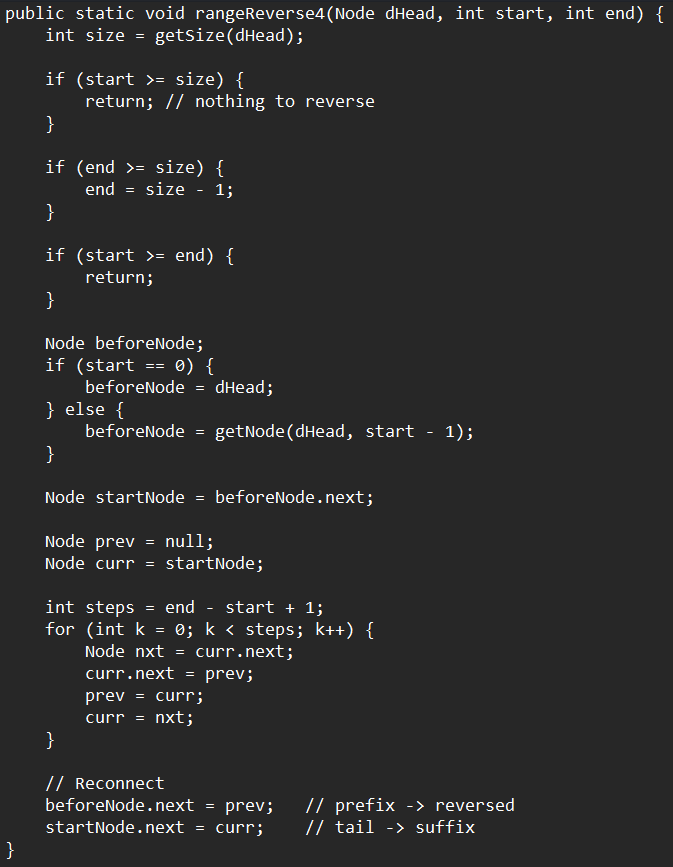

### Solution using getNode, getsize, reverseInPlace

In [ ]:
############################################
# reverseInPlace
############################################
def reverseInPlace(head):
    prev = None
    current = head

    while current != None:
        next_node = current.next
        current.next = prev
        prev = current
        current = next_node

    return prev     # new head of reversed part

# ===============================
# get_size(head)
# Counts real nodes (excluding dummy)
# ===============================
def get_size(head):
    if head.next == None:
        return 0

    count = 0
    current_node = head.next  # first real node (index 0)
    while current_node != None:
        count += 1
        current_node = current_node.next
    return count

# ===============================
# getNode(head, idx) - 0-based
# Returns node at index idx among real nodes
# ===============================
def getNode(head, idx):
    current = head.next  # index 0
    pos = 0
    while current is not None and pos < idx:
        current = current.next
        pos += 1
    return current  # may be None if idx invalid

def rangeReverse5(dHead, start, end):
    """
    dHead : dummy head (its next points to the real head)
    start : starting index (0-based)
    end   : ending index (0-based)
    """

    # ====================================================
    # 0. Determine list size
    # ====================================================
    size = get_size(dHead)

    # If start is beyond list → nothing to do
    if start >= size:
        return

    # Clamp end if needed (end bigger than list → reduce to last index)
    if end >= size:
        end = size - 1

    # If invalid or single-element segment → nothing to reverse
    if start >= end:
        return

    # ====================================================
    # 1. Find beforeStartNode and startNode using getNode()
    # ====================================================
    if start == 0:
        beforeStart = dHead               # beforeStart is dummy
    else:
        beforeStart = getNode(dHead, start - 1)

    startNode = beforeStart.next          # node at index start

    # ====================================================
    # 2. Find endNode and afterEnd using getNode()
    # ====================================================
    endNode = getNode(dHead, end)         # node at index end
    afterEnd = endNode.next               # node after the segment

    # IMPORTANT: Temporarily detach segment to reverse
    endNode.next = None

    # The slice startNode → ... → endNode is now isolated

    # ====================================================
    # 3. Reverse the isolated sublist using reverseInPlace()
    # ====================================================
    reversedHead = reverseInPlace(startNode)

    # ====================================================
    # 4. Reattach: prefix → reversed segment → suffix
    # ====================================================
    beforeStart.next = reversedHead        # attach prefix to reversed segment
    startNode.next = afterEnd              # attach reversed tail to suffix


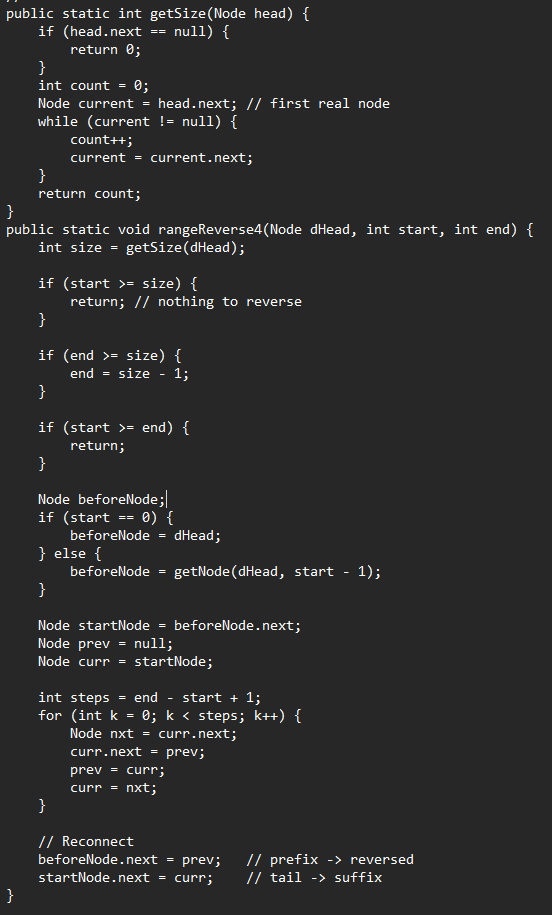

### Solution using Prepend logic


In [ ]:
############################################
def rangeReverse6(dHead, start, end):
    """
    Reverse nodes from index 'start' to 'end' (inclusive),
    move that reversed part to the start (right after dHead),
    and keep the rest in their original order afterward.
    """

    n = dHead      # start from dummy head
    i = 0

    # Move n so that n is the node BEFORE index 'start'
    while i != start and n.next is not None:
        n = n.next
        i += 1

    # Now repeatedly take n.next and move it right after dHead
    while i != end + 1 and n.next is not None:
        temp = n.next.next        # node after the one we're moving

        # Insert n.next right after dummy head
        n.next.next = dHead.next
        dHead.next = n.next

        # Fix the link after n
        n.next = temp

        i += 1

In [ ]:
############################################
# Node class
############################################
class Node:
    def __init__(self, elem, next=None):
        self.elem = elem
        self.next = next

############################################
# createList
############################################
def createList(arr):
    if len(arr) == 0:
        return None
    head = Node(arr[0])
    tail = head
    for i in range(1, len(arr)):
        tail.next = Node(arr[i])
        tail = tail.next
    return head

############################################
# printList
############################################
def printList(head):
    temp = head
    while temp:
        print(temp.elem, end=" -> " if temp.next else "")
        temp = temp.next
    print()

def test_range_reverse(fn, name):
    print("\n==============================")
    print(f"Testing {name}")
    print("==============================")

    print("===== EXAMPLE 1 =====")
    arr1 = [3, 5, 8, 7, 2, 1, 6, 4, 2]
    dHead1 = Node(-999)
    dHead1.next = createList(arr1)

    print("Original:")
    printList(dHead1.next)

    fn(dHead1, 2, 5)

    print("Modified:")
    printList(dHead1.next)


    print("\n===== EXAMPLE 2 =====")
    arr2 = [3, 5, 8, 7, 2, 1, 6, 4, 5]
    dHead2 = Node(-999)
    dHead2.next = createList(arr2)

    print("Original:")
    printList(dHead2.next)

    fn(dHead2, 4, 12)    # invalid end index → must be handled inside function

    print("Modified:")
    printList(dHead2.next)


test_range_reverse(rangeReverse1, "rangeReverse1") # Solution using ReverseInplace
test_range_reverse(rangeReverse2, "rangeReverse2") #Solution using without any methods
test_range_reverse(rangeReverse3, "rangeReverse3") # Solution using getNode
test_range_reverse(rangeReverse4, "rangeReverse4") # Solution using getNode, getsize
test_range_reverse(rangeReverse5, "rangeReverse5") # Solution using getNode, getsize, reverseInPlace
test_range_reverse(rangeReverse5, "rangeReverse6") # Solution using prepend logic



Testing rangeReverse1
===== EXAMPLE 1 =====
Original:
3 -> 5 -> 8 -> 7 -> 2 -> 1 -> 6 -> 4 -> 2
Modified:
1 -> 2 -> 7 -> 8 -> 3 -> 5 -> 6 -> 4 -> 2

===== EXAMPLE 2 =====
Original:
3 -> 5 -> 8 -> 7 -> 2 -> 1 -> 6 -> 4 -> 5
Modified:
5 -> 4 -> 6 -> 1 -> 2 -> 3 -> 5 -> 8 -> 7

Testing rangeReverse2
===== EXAMPLE 1 =====
Original:
3 -> 5 -> 8 -> 7 -> 2 -> 1 -> 6 -> 4 -> 2
Modified:
3 -> 2 -> 7 -> 8 -> 5 -> 1 -> 6 -> 4 -> 2

===== EXAMPLE 2 =====
Original:
3 -> 5 -> 8 -> 7 -> 2 -> 1 -> 6 -> 4 -> 5
Modified:
3 -> 5 -> 8 -> 5 -> 4 -> 6 -> 1 -> 2 -> 7

Testing rangeReverse3
===== EXAMPLE 1 =====
Original:
3 -> 5 -> 8 -> 7 -> 2 -> 1 -> 6 -> 4 -> 2
Modified:
3 -> 5 -> 1 -> 2 -> 7 -> 8 -> 6 -> 4 -> 2

===== EXAMPLE 2 =====
Original:
3 -> 5 -> 8 -> 7 -> 2 -> 1 -> 6 -> 4 -> 5
Modified:
3 -> 5 -> 8 -> 7 -> 5 -> 4 -> 6 -> 1 -> 2

Testing rangeReverse4
===== EXAMPLE 1 =====
Original:
3 -> 5 -> 8 -> 7 -> 2 -> 1 -> 6 -> 4 -> 2
Modified:
3 -> 5 -> 1 -> 2 -> 7 -> 8 -> 6 -> 4 -> 2

===== EXAMPLE 2 =====


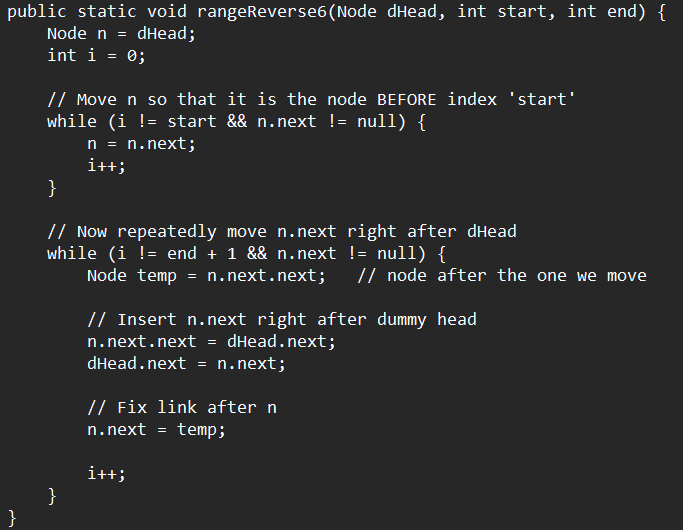

# Multi-dimentional array

## Maths

---------------------------------------------------------------------

### Summer2025 Q1 i)

Question: Given a 3D array index [1][2][3] from an array with dimensions 2×3×4, determine whether there exists a corresponding valid 2D array index [i][j] in a 2D array of dimensions 5×3 that maps to the same linear index. If such a 2D index exists, provide it. If not, explain why it is invalid.

####Solution:
    - 3D to 1D Mapping:
    
    - Given,
        - 3D index of an elemet is (w, x, y ) = (1, 2, 3)
        - 3D dimention  is MxNxO = 2×3×4


    - The array length in 1D will be = MxNxO=2×3×4=6x4=24
        - index_of_linear_array = w × (N×O) + x ×(O) + y
        - index_of_linear_array = 1 × (3×4) + 2 ×(4) + 3
        - index_of_linear_array = 23

    - Given,
        - 2D array of dimensions 5×3 that maps to the same linear index where M=5, N=3
        - The array length in 1D will be = MxN=5x3=15, valid range of indexes 0 to 14.
        - Hence, index 23 cannot exists in a array of length 15. Index Does not exist

 ==========================================================

### Fall2025 Q4 i)

Suppose you are given a multi-dimensional array with dimensions **6 × 4 × 8**.  

What is the linear index of **[4][2][5]**?

---

#### Given:

- dimension of the 3D array 6 × 4 × 8.
- index of a value in 3D array is = [4][2][5]
- Let's assume, (w, x, y) = (4, 2, 5). So, w = 4, x = 2, y = 5
- find: We need to find the index of the same value in the 1D array. (3D → 1D)

Since the array has dimension 6 × 4 × 8, Then, M = 6, N = 4, O = 8
And the equation for getting the linear index will be:

- linear_index = W × (N × O) + X × O + Y
- linear_index = 4 × (4 × 8) + 2 × 8 + 5
- linear_index = 4 × 32 + 16 + 5
- linear_index = 128 + 16 + 5
- linear_index = 149

Final Answer: The linear index of [4][2][5] is 149.


## Fall2025: Q1: Block Energy


In [ ]:
def blockEnergySum1(grid, directions):
    rows = len(grid)
    cols = len(grid[0])

    # Output matrix
    energy = [[0] * cols for _ in range(rows)]

    for row_no in range(rows):
        for col_no in range(cols):

            # Get direction as a string
            d = directions[row_no][col_no]

            # Set dx, dy based on direction (no dictionary)
            if d == "NE":
                dx, dy = -1,  1
            elif d == "NW":
                dx, dy = -1, -1
            elif d == "SE":
                dx, dy =  1,  1
            elif d == "SW":
                dx, dy =  1, -1
            else:
                # In case of an unknown direction, treat energy as 0
                dx, dy = 0, 0

            r, c = row_no, col_no
            total = 0

            # move diagonally until you exit grid
            while 0 <= r < rows and 0 <= c < cols:
                total += grid[r][c]
                r += dx
                c += dy

            energy[row_no][col_no] = total

    return energy


grid = [
    [1,  2,  3,  4],
    [5,  6,  7,  8],
    [9, 10, 11, 12],
    [13,14, 15, 16]
]

directions = [
    ["SE","SE","SW","NE"],
    ["SW","SW","NE","SE"],
    ["NW","SW","NE","NW"],
    ["SE","NW","SW","NE"]
]

print(blockEnergySum1(grid, directions))

[[34, 21, 18, 4], [5, 15, 11, 8], [9, 23, 19, 21], [13, 23, 15, 16]]


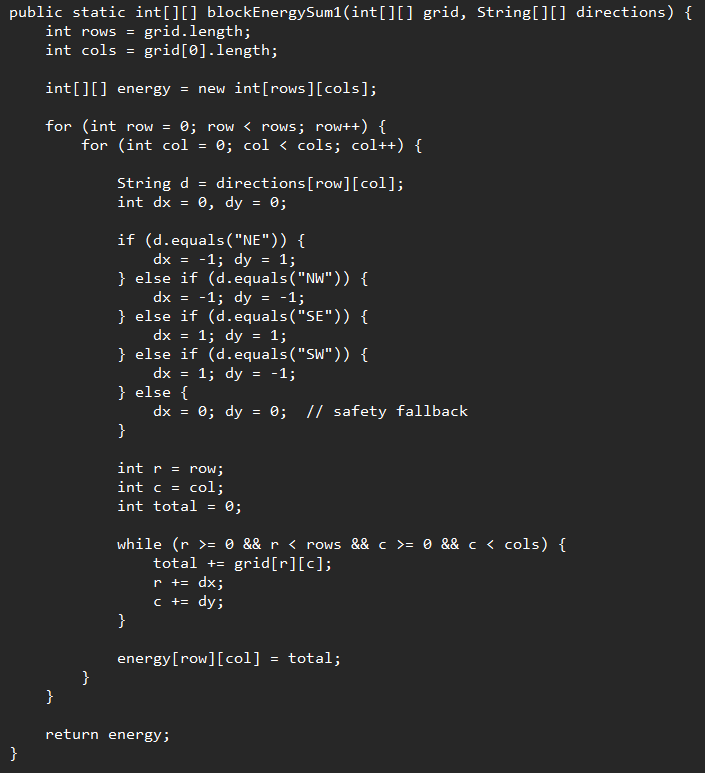

In [ ]:
def blockEnergySum2(grid, directions):
    rows = len(grid)
    cols = len(grid[0])

    energy = [[0] * cols for _ in range(rows)]

    for row_no in range(rows):
        for col_no in range(cols):

            direction = directions[row_no][col_no]

            # Determine movement based on direction
            if direction == "NE":
                dx, dy = -1, 1
            elif direction == "NW":
                dx, dy = -1, -1
            elif direction == "SE":
                dx, dy = 1, 1
            elif direction == "SW":
                dx, dy = 1, -1
            # no fallback; assume input is always valid

            # Call helper to compute diagonal sum
            energy[row_no][col_no] = diagonal_sum(
                grid, row_no, col_no, dx, dy
            )

    return energy

def diagonal_sum(grid, start_r, start_c, dx, dy):
    rows = len(grid)
    cols = len(grid[0])
    total = 0
    r, c = start_r, start_c

    while 0 <= r < rows and 0 <= c < cols:
        total += grid[r][c]
        r += dx
        c += dy

    return total


grid = [
    [1,  2,  3,  4],
    [5,  6,  7,  8],
    [9, 10, 11, 12],
    [13,14, 15, 16]
]

directions = [
    ["SE","SE","SW","NE"],
    ["SW","SW","NE","SE"],
    ["NW","SW","NE","NW"],
    ["SE","NW","SW","NE"]
]

print(blockEnergySum2(grid, directions))

[[34, 21, 18, 4], [5, 15, 11, 8], [9, 23, 19, 21], [13, 23, 15, 16]]


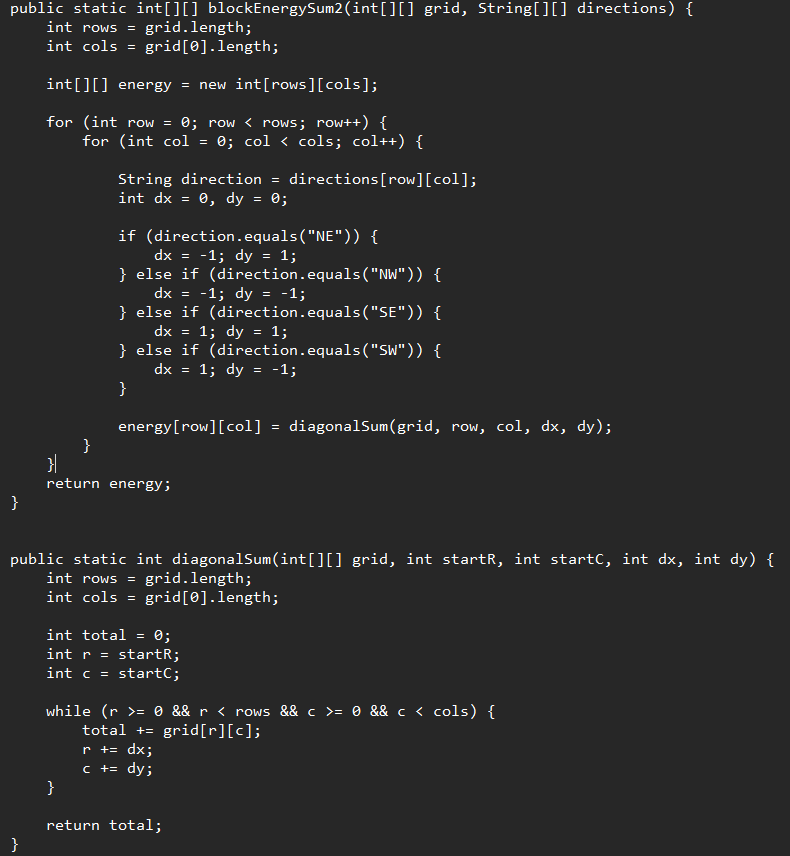

## Summer2025: Local Minima

- Only valid cells (below threshold) are checked.
- The center value must be strictly less than all its valid neighbors.
- Among multiple valid local minima, the one that appears last (bottom-right most) is chosen.

In [ ]:
def localMinima2_with_list(matrix, threshold):
    rows = len(matrix)
    cols = len(matrix[0])

    # Default result if no local minimum is found
    result = (-1, -1, -1)

    results = []  # List to store all valid local minima

    # Loop through the internal cells (excluding border cells)
    #--making sure all 4 neighbors exists
    for i in range(1, rows - 1):
        for j in range(1, cols - 1):
            center = matrix[i][j]

            # Skip this cell if it exceeds the noise threshold
            if center > threshold:
                continue

            is_local_min = True  # Assume current cell is a local minimum

            # Check UP neighbor
            up = matrix[i - 1][j]
            if up <= threshold and center >= up:
                is_local_min = False  # Not a local min if neighbor is smaller or equal

            # Check DOWN neighbor
            down = matrix[i + 1][j]
            if down <= threshold and center >= down:
                is_local_min = False

            # Check LEFT neighbor
            left = matrix[i][j - 1]
            if left <= threshold and center >= left:
                is_local_min = False

            # Check RIGHT neighbor
            right = matrix[i][j + 1]
            if right <= threshold and center >= right:
                is_local_min = False

            # If the current cell is smaller than all valid neighbors
            if is_local_min:
                result = (i, j, center)  # Save the current local minimum
                results.append(result)  # Also store in results list

    # Debug print (optional): Show all found local minima
    print("results", results)

    # Return the last found local minimum (bottom-right most)
    if results:
        result = results[-1]

    return result


# Driver code
matrix = [
    [22, 21, 1000, 23],
    [25, 17, 21, 1000],
    [1000, 19, 18, 22],
    [21, 22, 1000, 20]
]
threshold = 100
##################################################
print('-'*100)
i, j, val = localMinima2_with_list(matrix, threshold)

if val != -1:
    print(f"Local minimum found at: ({i}, {j})")
    print(f"Value: {val}")
else:
    print("No valid local minimum found.")

----------------------------------------------------------------------------------------------------
results [(1, 1, 17), (2, 2, 18)]
Local minimum found at: (2, 2)
Value: 18


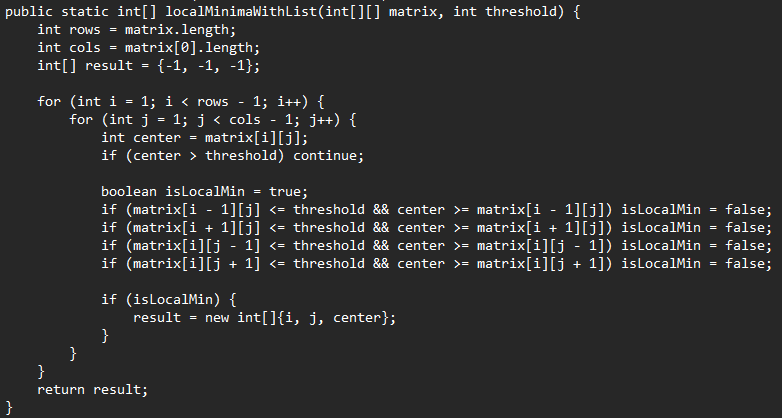